# Учимся работе с данными - от загрузки до моделирования

         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   symmetry_mean  fractal_dimension_mean  radius_se  texture_s

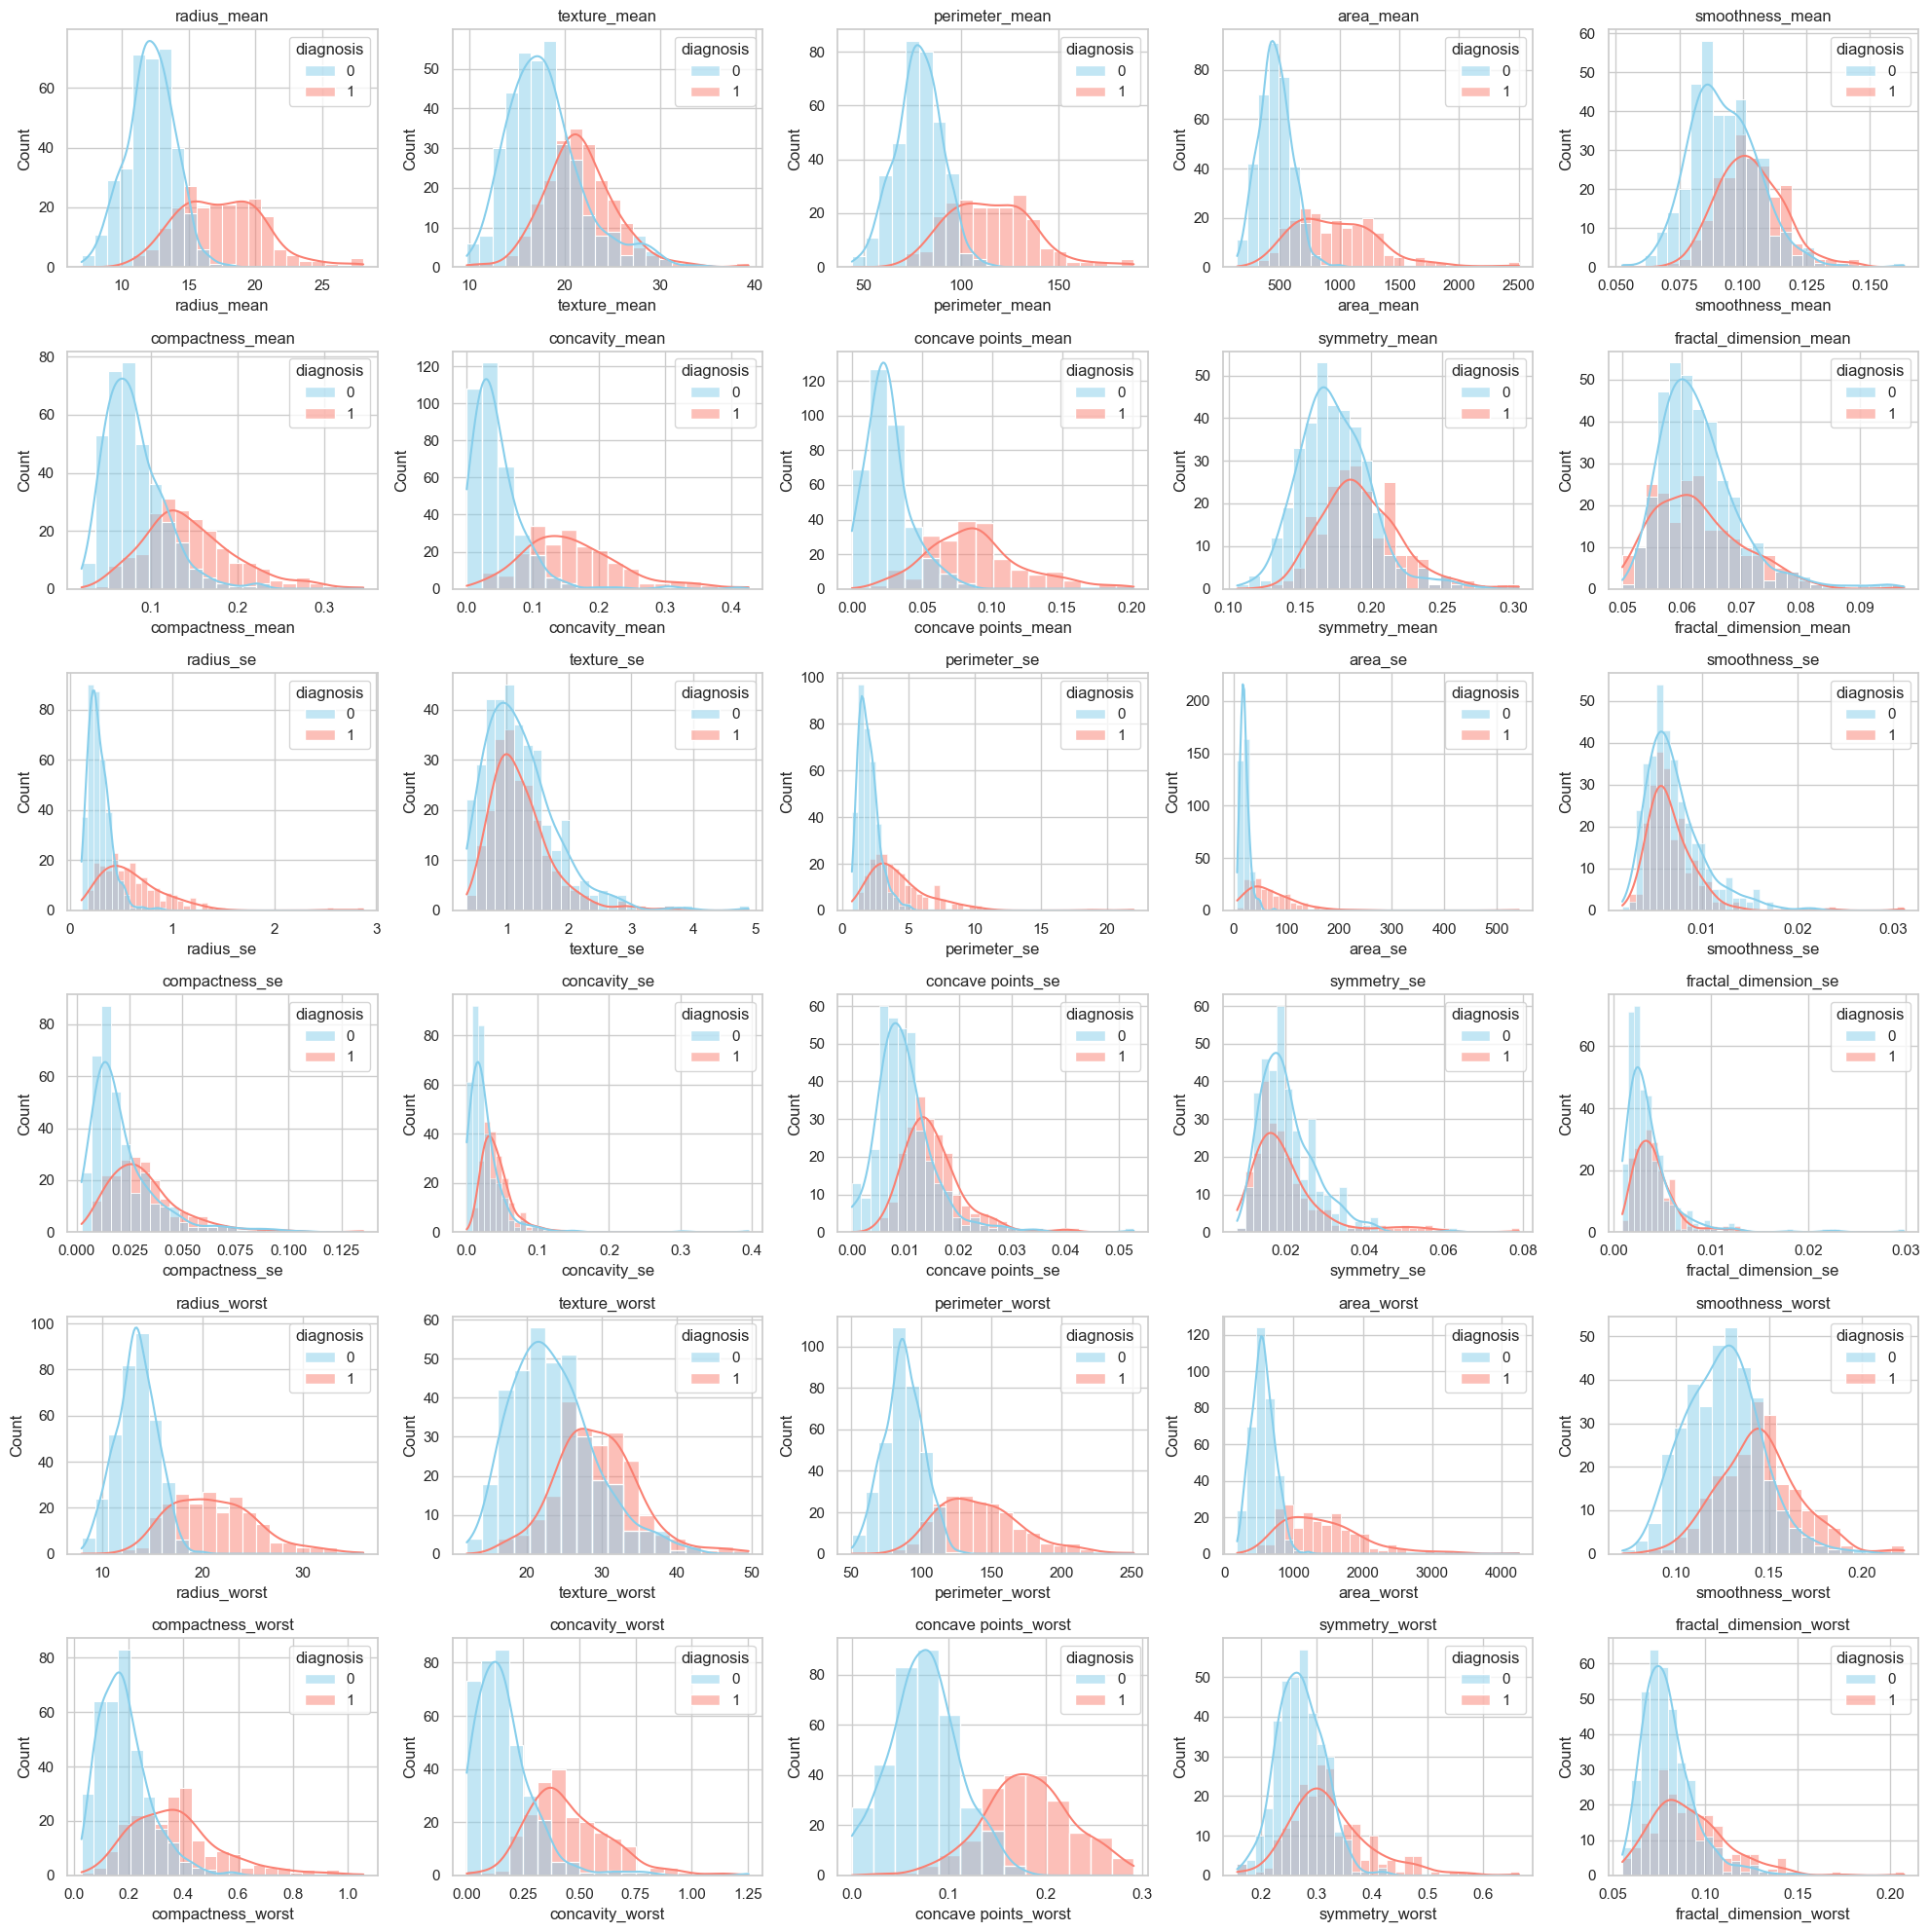

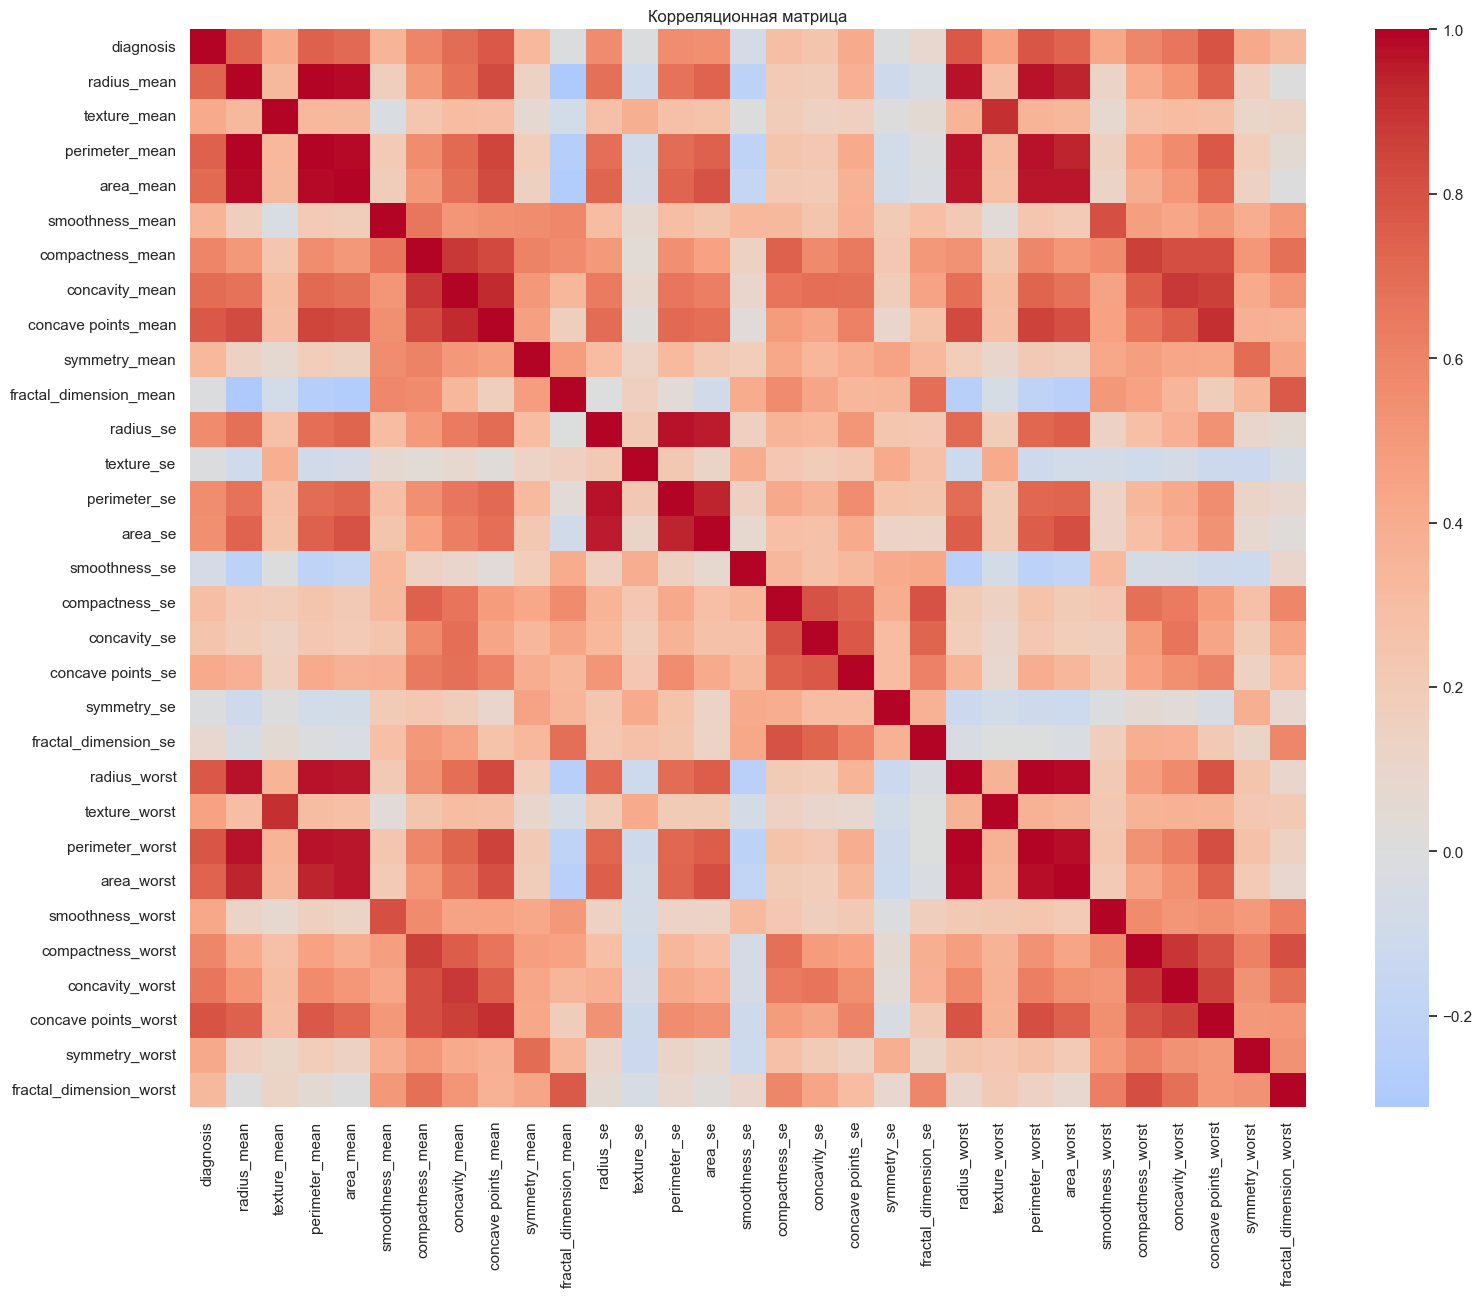

Сильно скоррелированные пары:
 radius_mean      perimeter_mean     0.997855
perimeter_mean   radius_mean        0.997855
perimeter_worst  radius_worst       0.993708
radius_worst     perimeter_worst    0.993708
radius_mean      area_mean          0.987357
area_mean        radius_mean        0.987357
                 perimeter_mean     0.986507
perimeter_mean   area_mean          0.986507
area_worst       radius_worst       0.984015
radius_worst     area_worst         0.984015
perimeter_worst  area_worst         0.977578
area_worst       perimeter_worst    0.977578
perimeter_se     radius_se          0.972794
radius_se        perimeter_se       0.972794
perimeter_worst  perimeter_mean     0.970387
perimeter_mean   perimeter_worst    0.970387
radius_mean      radius_worst       0.969539
radius_worst     radius_mean        0.969539
                 perimeter_mean     0.969476
perimeter_mean   radius_worst       0.969476
dtype: float64


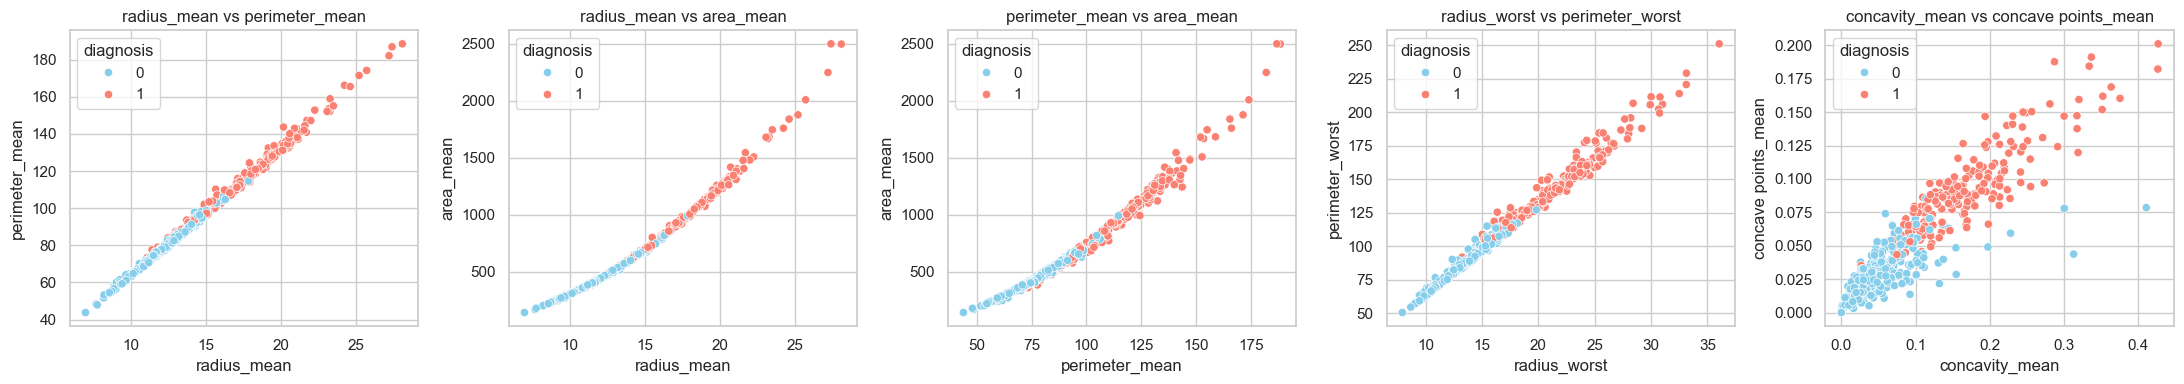

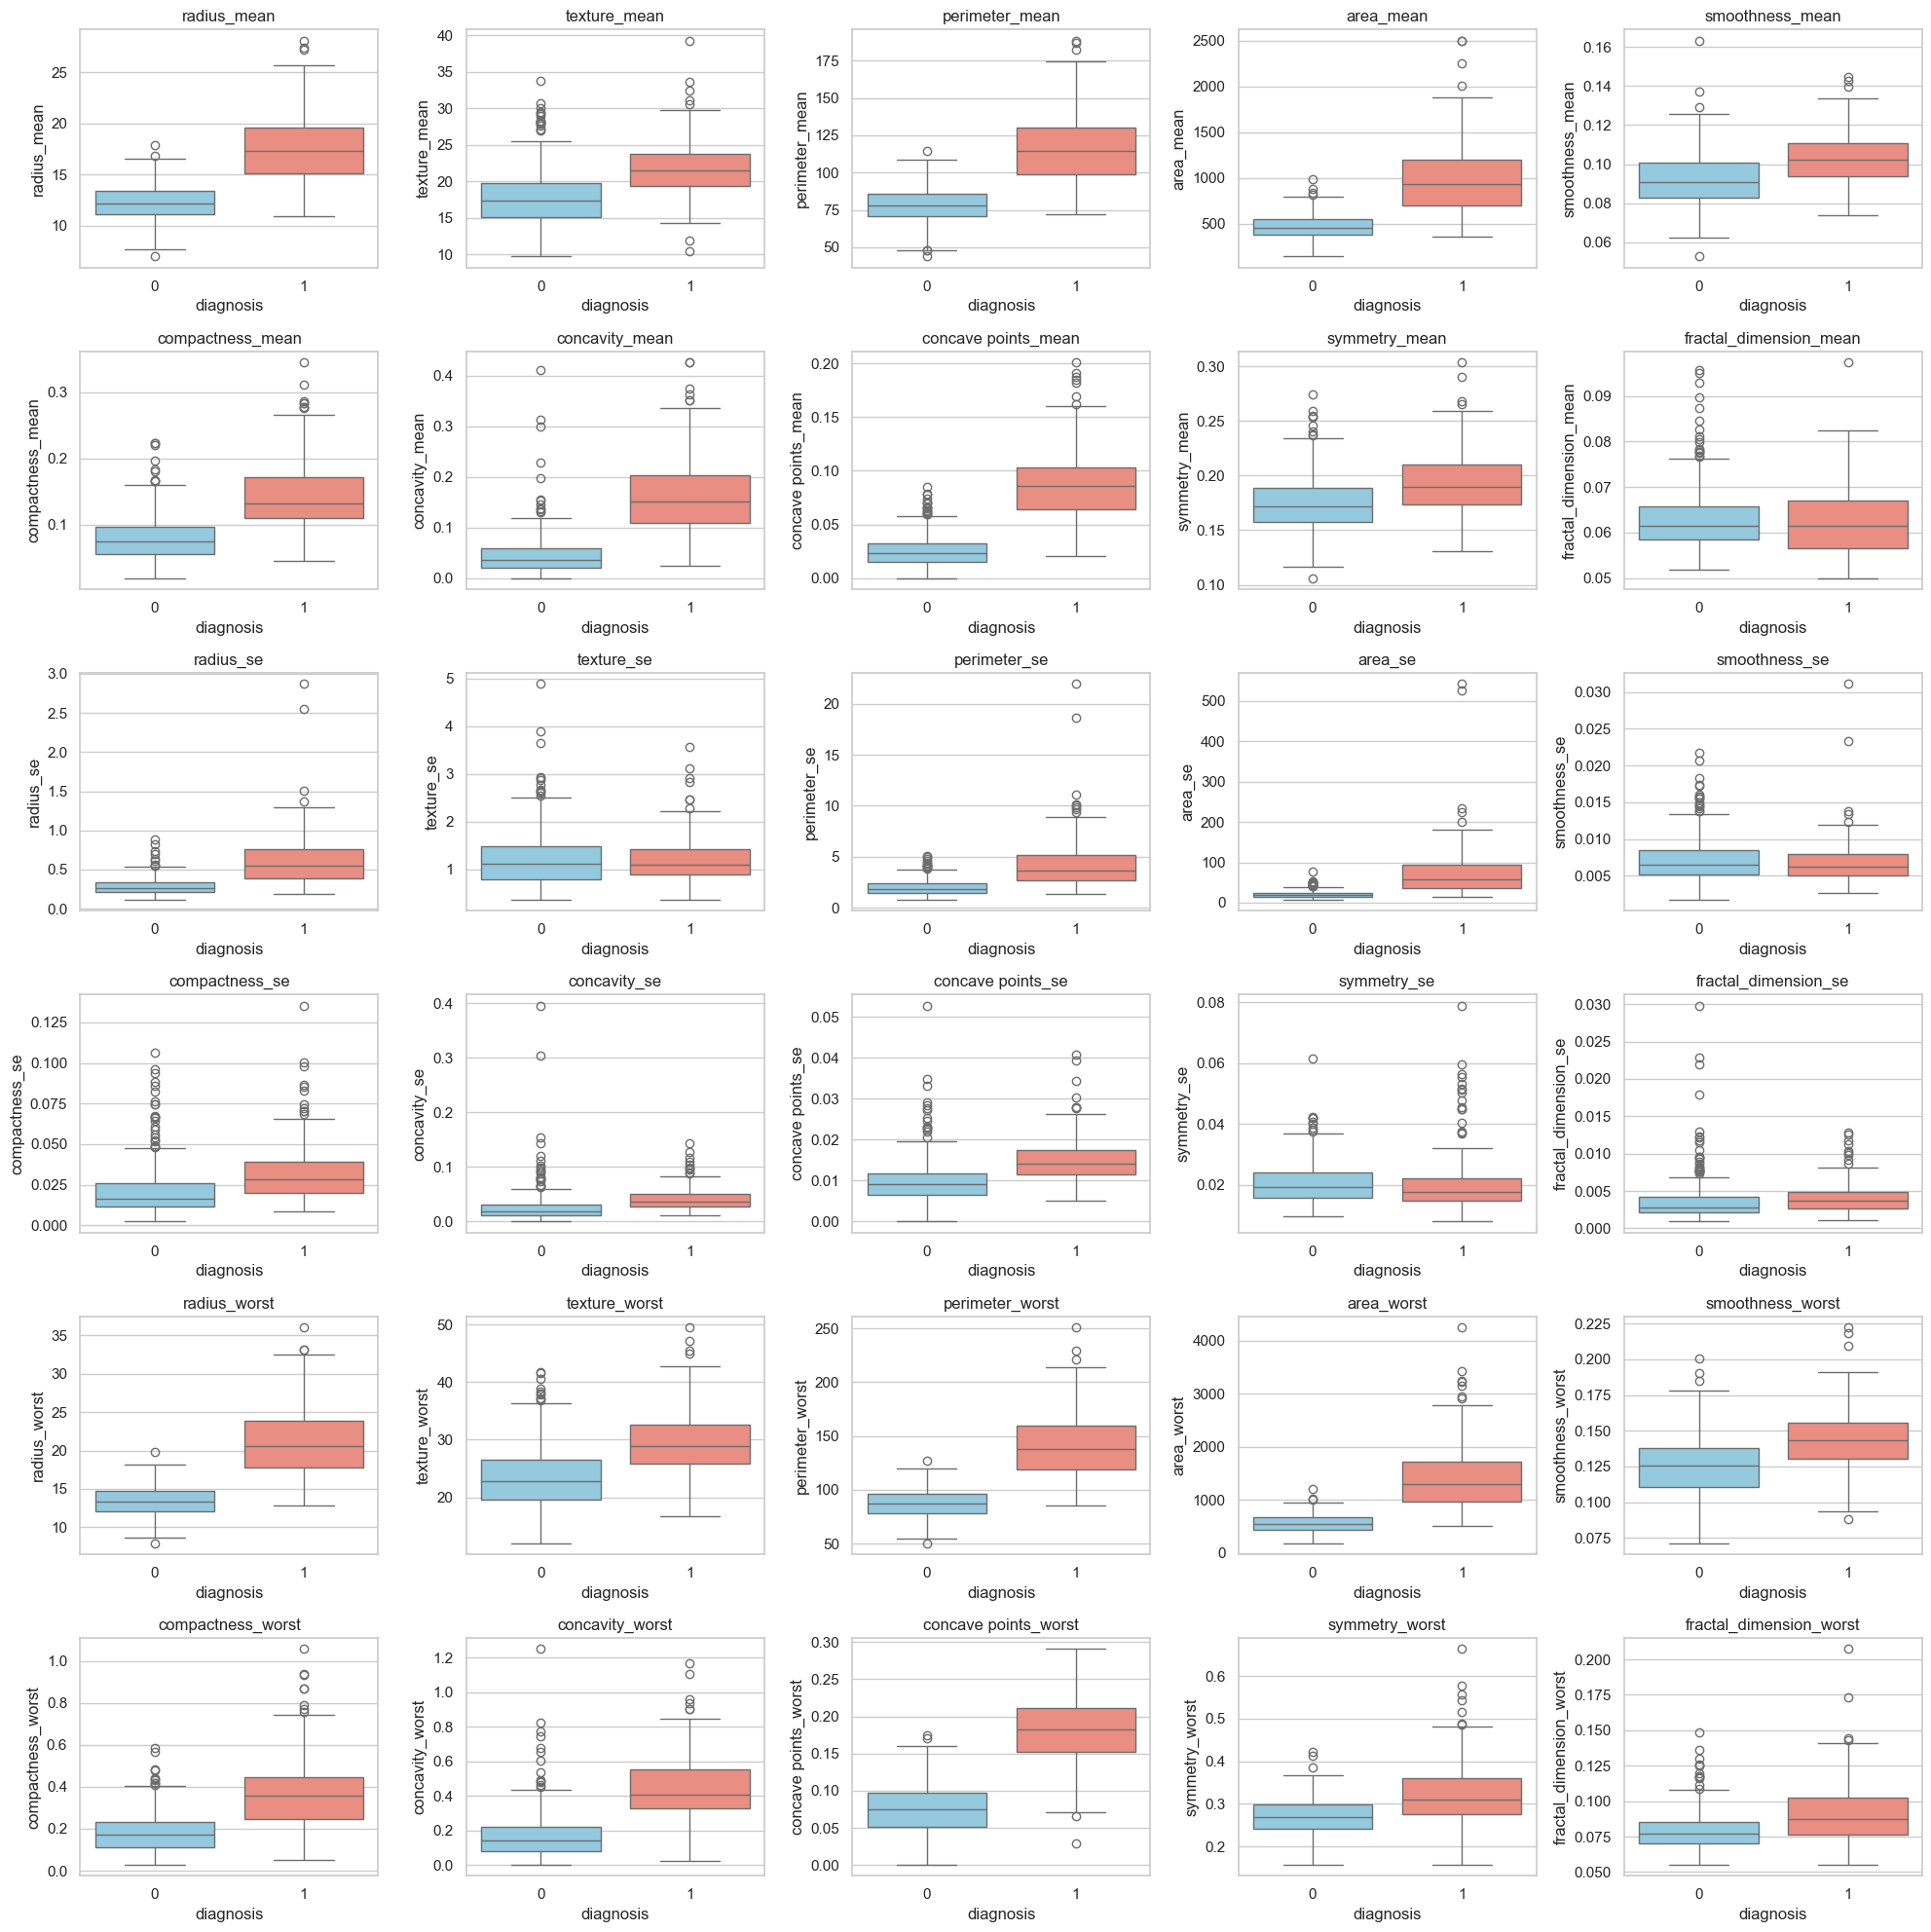

=== kNN (default) ===
Accuracy : 0.9649122807017544
Precision: 1.0
Recall   : 0.90625
F1       : 0.9508196721311475
ROC AUC  : 0.9881717289719626


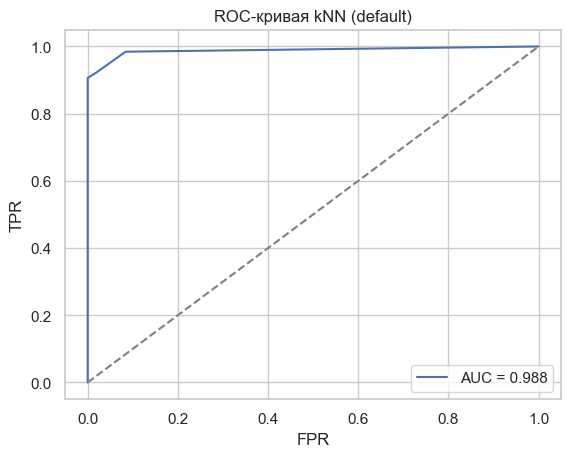

Лучшее k: 5


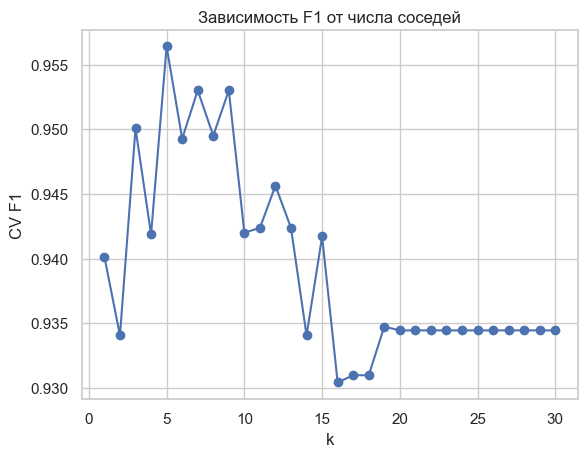

=== kNN (best k) ===
Accuracy : 0.9649122807017544
Precision: 1.0
Recall   : 0.90625
F1       : 0.9508196721311475
ROC AUC  : 0.9881717289719626


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score,
                             roc_curve, roc_auc_score)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

# 1. ЗАГРУЗКА ДАННЫХ
df = pd.read_csv("data.csv")
print(df.head())
print(df.info())
print(df.describe().T)
print(df["diagnosis"].value_counts())

# Убираем лишние столбцы и кодируем целевую переменную
df = df.drop(columns=["id", "Unnamed: 32"])
df["diagnosis"] = df["diagnosis"].map({"B": 0, "M": 1})


# 2. EDA
features = df.columns.drop("diagnosis")

# 2.1. Гистограммы с группировкой по diagnosis
fig, axes = plt.subplots(6, 5, figsize=(20, 20))
axes = axes.flatten()
for i, col in enumerate(features):
    sns.histplot(data=df, x=col, hue="diagnosis", kde=True,
                 palette={0: "skyblue", 1: "salmon"}, ax=axes[i])
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

# 2.2. Тепловая карта корреляций
plt.figure(figsize=(18, 14))
corr = df.corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Корреляционная матрица")
plt.show()

corr_pairs = corr.abs().unstack().sort_values(ascending=False)
strong = corr_pairs[(corr_pairs > 0.85) & (corr_pairs < 1.0)]
print("Сильно скоррелированные пары:\n", strong.head(20))

# 2.3. Диаграммы рассеяния для сильно скоррелированных признаков
pairs = [
    ("radius_mean", "perimeter_mean"),
    ("radius_mean", "area_mean"),
    ("perimeter_mean", "area_mean"),
    ("radius_worst", "perimeter_worst"),
    ("concavity_mean", "concave points_mean"),
]
fig, axes = plt.subplots(1, len(pairs), figsize=(22, 4))
for ax, (x, y) in zip(axes, pairs):
    sns.scatterplot(data=df, x=x, y=y, hue="diagnosis",
                    palette={0: "skyblue", 1: "salmon"}, ax=ax)
    ax.set_title(f"{x} vs {y}")
plt.tight_layout()
plt.show()

# 2.4. Boxplot с группировкой
fig, axes = plt.subplots(6, 5, figsize=(20, 20))
axes = axes.flatten()
for i, col in enumerate(features):
    sns.boxplot(data=df, x="diagnosis", y=col, ax=axes[i],
                hue="diagnosis", palette={0: "skyblue", 1: "salmon"},
                dodge=False, legend=False)
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

# 3. TRAIN/TEST SPLIT + СТАНДАРТИЗАЦИЯ

X = df.drop(columns="diagnosis")
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# 4. kNN

knn = KNeighborsClassifier()
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)
y_proba = knn.predict_proba(X_test_scaled)[:, 1]

print("=== kNN (default) ===")
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1       :", f1_score(y_test, y_pred))
print("ROC AUC  :", roc_auc_score(y_test, y_proba))

fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_proba):.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("FPR"); plt.ylabel("TPR")
plt.title("ROC-кривая kNN (default)")
plt.legend(); plt.show()


# 5. ПОДБОР k ЧЕРЕЗ КРОСС-ВАЛИДАЦИЮ

k_values = range(1, 31)
cv_scores = []
for k in k_values:
    knn_k = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn_k, X_train_scaled, y_train,
                             cv=5, scoring="f1")
    cv_scores.append(scores.mean())

best_k = k_values[int(np.argmax(cv_scores))]
print("Лучшее k:", best_k)

plt.plot(k_values, cv_scores, marker="o")
plt.xlabel("k"); plt.ylabel("CV F1")
plt.title("Зависимость F1 от числа соседей")
plt.show()

knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train_scaled, y_train)
y_pred_b = knn_best.predict(X_test_scaled)
y_proba_b = knn_best.predict_proba(X_test_scaled)[:, 1]

print("=== kNN (best k) ===")
print("Accuracy :", accuracy_score(y_test, y_pred_b))
print("Precision:", precision_score(y_test, y_pred_b))
print("Recall   :", recall_score(y_test, y_pred_b))
print("F1       :", f1_score(y_test, y_pred_b))
print("ROC AUC  :", roc_auc_score(y_test, y_proba_b))

